# 07 — Chọn ngưỡng cho ST-DBSCAN

NB06 chọn ngưỡng cho stay-point (D, T, max_gap). Notebook này đo các ngưỡng tương ứng cho **ST-DBSCAN** (Birant & Kut, 2007):
hai điểm là láng giềng khi cách nhau ≤ eps1 về không gian **và** ≤ eps2 về thời gian. Cụm thu được gọi là **episode** (một lần ở một chỗ).

Câu hỏi:
1. **Mật độ đo bằng gì?** ST-DBSCAN gốc đếm số điểm (MinPts). Số điểm của cùng một lần dừng chênh nhau vài lần giữa thiết bị và năm (NB01 mục 5),
   và phần lớn thời gian dừng nằm trong khoảng không ghi (NB05 mục 3). Thay số điểm bằng **thời lượng** thì có ràng buộc gì giữa eps2 và ngưỡng mật độ?
2. **eps2:** bao nhiêu thì episode ít bị chẻ, ít nhận nhầm lúc đi xe là dừng, và cho cùng home/office như stay-point?
3. **Thưa hoá điểm** (để chạy nhanh) có làm đổi kết quả không?
4. **Điều kiện quay lại sau khoảng không ghi:** đo giữa hai điểm liên tiếp (như NB06 mục 2) hay nới ra như stay-point?

eps1 = 200 m và ngưỡng thời lượng 20 phút lấy theo NB06 mục 1 (D, T), max_gap = 48 h theo NB06 mục 2.
Dữ liệu chuẩn bị giống NB06. Nhãn phương tiện chỉ dùng làm kiểm tra chéo như NB06.

In [1]:
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numba import njit
from sklearn.cluster import DBSCAN

from utils import add_calendar, add_geo, china_calendar, haversine, load_points, savefig, setup_style

setup_style()
MOTOR = ["bus", "car", "taxi", "subway", "train", "airplane", "motorcycle", "boat"]
EPS1, MIN_DUR, MAX_GAP = 200.0, 20 * 60.0, 48 * 3600.0

pts = load_points(["user", "traj_id", "lat", "lon", "ts_utc", "mode"])
pts = pts[pts.lat.between(-90, 90) & (pts.ts_utc.dt.year >= 2007)]
pts = pts.sort_values(["user", "ts_utc"], kind="stable").drop_duplicates(["user", "ts_utc"]).reset_index(drop=True)
pts = add_calendar(add_geo(pts))
ts = pts.ts_utc.to_numpy().astype("datetime64[s]").astype(np.int64).astype(np.float64)
off = pts.utc_offset_h.to_numpy() * 3600
lat, lon = pts.lat.to_numpy(), pts.lon.to_numpy()
mode = pts["mode"].astype(str).to_numpy()
labeled = pts["mode"].notna().to_numpy()
motor = labeled & np.isin(mode, MOTOR)
users = pts.user.to_numpy()
same_user = np.r_[False, users[1:] == users[:-1]]
dtu = np.where(same_user, np.r_[0, np.diff(ts)], 0)
idx_user = pts.groupby("user").indices
print(f"{len(pts):,} điểm, {len(idx_user)} user")

24,178,074 điểm, 182 user


## Chuẩn bị: stay-point làm mốc so sánh

Stay-point, place, giờ đêm / giờ hành chính giống hệt NB06 (D = 200 m, T = 20 phút, max_gap = 48 h). Home = place có nhiều giờ đêm nhất;
office ứng viên = place khác home có nhiều giờ hành chính nhất (NB06 mục 5).

In [2]:
@njit
def _hav(a1, o1, a2, o2):
    r = np.pi / 180
    x = np.sin((a2 - a1) * r / 2) ** 2 + np.cos(a1 * r) * np.cos(a2 * r) * np.sin((o2 - o1) * r / 2) ** 2
    return 2 * 6371008.8 * np.arcsin(np.sqrt(x))


@njit
def stay_points(lat, lon, t, D, T):
    n = len(lat); out = []; i = 0
    while i < n:
        j = i + 1
        while j < n and _hav(lat[i], lon[i], lat[j], lon[j]) <= D:
            j += 1
        if t[j - 1] - t[i] >= T:
            out.append((i, j - 1)); i = j
        else:
            i += 1
    return out


def detect(D, T, max_gap_h=None):
    rows = [(idx[i], idx[j]) for idx in idx_user.values() for i, j in stay_points(lat[idx], lon[idx], ts[idx], D, T)]
    s = np.array(rows)
    if max_gap_h is not None:
        mg = np.array([dtu[a + 1:b + 1].max() if b > a else 0 for a, b in s]) / 3600
        s = s[mg <= max_gap_h]
    return s


def add_place(st):
    lab = np.full(len(st), -1)
    for idx in st.groupby("user").indices.values():
        X = np.radians(st.iloc[idx][["lat", "lon"]].to_numpy())
        lab[idx] = DBSCAN(eps=200 / 6371008.8, min_samples=1, metric="haversine").fit_predict(X)
    st["place"] = lab
    return st


def stay_table(s):
    a, b = s[:, 0], s[:, 1]
    cs_a, cs_o = np.r_[0, np.cumsum(lat)], np.r_[0, np.cumsum(lon)]
    n = b - a + 1
    st = pd.DataFrame({"user": users[a],
                       "start": pd.to_datetime(ts[a] + off[a], unit="s"), "end": pd.to_datetime(ts[b] + off[a], unit="s"),
                       "in_china": pts.in_china.to_numpy()[a],
                       "lat": (cs_a[b + 1] - cs_a[a]) / n, "lon": (cs_o[b + 1] - cs_o[a]) / n})
    st["dur_h"] = (st.end - st.start).dt.total_seconds() / 3600
    return add_place(st)


CAL_WORK = china_calendar().set_index("date").is_workday


def window_hours(st):
    rec = []
    for r in st.itertuples():
        for h in pd.date_range(r.start.floor("h"), r.end, freq="h"):
            ov = (min(h + pd.Timedelta(hours=1), r.end) - max(h, r.start)).total_seconds() / 3600
            if ov > 0:
                rec.append((r.Index, r.user, r.place, r.in_china, h, ov))
    x = pd.DataFrame(rec, columns=["sid", "user", "place", "in_china", "h", "hrs"])
    hr = x.h.dt.hour
    cn = CAL_WORK.reindex(x.h.dt.normalize()).to_numpy()
    workday = np.where(x.in_china & ~pd.isna(cn), cn, x.h.dt.day_of_week < 5).astype(bool)
    x["night"] = (hr >= 22) | (hr < 6)
    x["work"] = workday & hr.between(9, 17)
    x["night_date"] = (x.h - pd.Timedelta(hours=6)).dt.normalize()
    x["date"] = x.h.dt.normalize()
    return x


def place_summary(st, wh):
    n = wh[wh.night].groupby(["user", "place"]).agg(night_h=("hrs", "sum"), nights=("night_date", "nunique"))
    w = wh[wh.work].groupby(["user", "place"]).agg(work_h=("hrs", "sum"), workdays=("date", "nunique"))
    xy = st.groupby(["user", "place"])[["lat", "lon"]].mean()
    return xy.join(n).join(w).fillna(0).reset_index()


def home_office(ps):
    home = ps[ps.night_h > 0].sort_values("night_h", ascending=False).groupby("user").head(1).set_index("user")
    other = ps.merge(home[["place"]].rename(columns={"place": "hp"}), left_on="user", right_index=True).query("place != hp")
    office = other[other.work_h > 0].sort_values("work_h", ascending=False).groupby("user").head(1).set_index("user")
    return home[["lat", "lon"]], office[["lat", "lon"]]


def frag_share(st):
    # NB06 mục 1.2: mảnh của cùng một lần dừng = bắt đầu ≤ 15 phút sau khi cái trước kết thúc, hai tâm cách ≤ 250 m
    st = st.sort_values(["user", "start"])
    nxt = st.groupby("user").shift(-1)
    gap_min = (nxt.start - st.end).dt.total_seconds() / 60
    return ((gap_min <= 15) & (haversine(st.lat, st.lon, nxt.lat, nxt.lon) <= 250)).mean()


def agree(a, b):
    u = a.index.intersection(b.index)
    d = haversine(a.loc[u, "lat"], a.loc[u, "lon"], b.loc[u, "lat"], b.loc[u, "lon"])
    return len(u), (d <= 200).mean()


t0 = time.time()
s_ref = detect(200, MIN_DUR, max_gap_h=48)
st_ref = stay_table(s_ref)
home_ref, office_ref = home_office(place_summary(st_ref, window_hours(st_ref)))
n = s_ref[:, 1] - s_ref[:, 0] + 1
cs_l, cs_m = np.r_[0, np.cumsum(labeled)], np.r_[0, np.cumsum(motor)]
ls = (cs_l[s_ref[:, 1] + 1] - cs_l[s_ref[:, 0]]) / n
ms = (cs_m[s_ref[:, 1] + 1] - cs_m[s_ref[:, 0]]) / n
ref_fake = ((ms / np.maximum(ls, 1e-9) >= .5) & (ls >= .5)).sum() / (ls >= .5).sum()
print(f"Stay-point mốc: {len(st_ref):,} stay, {st_ref.dur_h.sum():,.0f} giờ, home {len(home_ref)} user, "
      f"office ứng viên {len(office_ref)} user, fragment {frag_share(st_ref):.1%}, stay giả {ref_fake:.1%} ({time.time() - t0:.0f} s)")

Stay-point mốc: 23,944 stay, 101,885 giờ, home 168 user, office ứng viên 149 user, fragment 14.2%, stay giả 22.6% (7 s)


## Chuẩn bị: thời lượng của từng điểm và thưa hoá

**Thời lượng của điểm i:** `w_i = dt` tới điểm kế tiếp của cùng user, nếu điểm kế tiếp nằm trong eps1 = 200 m và dt ≤ 48 h; ngược lại `w_i = 0`.
Đây là cùng giả định với stay-point: khoảng không ghi ≤ 48 h mà user xuất hiện lại trong 200 m thì coi như user ở yên đó (NB06 mục 2).
Điểm đang di chuyển với nhịp ghi vài giây chỉ mang vài giây.

**Thưa hoá:** gộp điểm của cùng user trong cùng một ô thời gian (10 s hoặc 60 s): toạ độ là trung bình, thời lượng là **tổng** `w_i`,
nên tổng thời gian không đổi. Số điểm có nhãn / có nhãn cơ giới cũng được cộng dồn để tính stay giả như NB06.

In [3]:
nxt_same = np.r_[same_user[1:], False]
dt_next = np.r_[np.diff(ts), 0.0]
d_next = np.r_[haversine(lat[:-1], lon[:-1], lat[1:], lon[1:]), np.inf]
w = np.where(nxt_same & (dt_next <= MAX_GAP) & (d_next <= EPS1), dt_next, 0.0)
print(f"Tổng thời lượng gán cho điểm: {w.sum() / 3600:,.0f} giờ; trong đó từ khoảng không ghi ≥ 1 h: {w[dt_next >= 3600].sum() / w.sum():.1%}")


def thin(bucket_s, w=w):
    # ô thời gian theo user; điểm đã sort (user, ts) nên ô mới bắt đầu khi đổi user hoặc đổi ô
    b = np.floor(ts / bucket_s)
    start = np.r_[True, (users[1:] != users[:-1]) | (b[1:] != b[:-1])]
    g = np.flatnonzero(start)
    cnt = np.diff(np.r_[g, len(ts)])
    out = pd.DataFrame({"user": users[g], "t": ts[g], "off": off[g], "in_china": pts.in_china.to_numpy()[g],
                        "lat": np.add.reduceat(lat, g) / cnt, "lon": np.add.reduceat(lon, g) / cnt,
                        "w": np.add.reduceat(w, g), "n": cnt,
                        "n_lab": np.add.reduceat(labeled.astype(np.int64), g), "n_mot": np.add.reduceat(motor.astype(np.int64), g)})
    out["t_end"] = ts[np.r_[g[1:], len(ts)] - 1] + w[np.r_[g[1:], len(ts)] - 1]
    return out


T10 = thin(10)
print(f"Thưa hoá 10 s: {len(pts):,} -> {len(T10):,} điểm ({len(T10) / len(pts):.1%}); tổng thời lượng giữ nguyên: {np.isclose(T10.w.sum(), w.sum())}")
display(T10.head())

Tổng thời lượng gán cho điểm: 100,860 giờ; trong đó từ khoảng không ghi ≥ 1 h: 72.7%


Thưa hoá 10 s: 24,178,074 -> 6,691,803 điểm (27.7%); tổng thời lượng giữ nguyên: True


,user,t,off,in_china,lat,lon,w,n,n_lab,n_mot,t_end
0,0,"1,224,730,384.0000","28,800.0000",True,39.9847,116.3184,6.0000,1,0,0,"1,224,730,390.0000"
1,0,"1,224,730,390.0000","28,800.0000",True,39.9847,116.3184,10.0000,2,0,0,"1,224,730,400.0000"
2,0,"1,224,730,400.0000","28,800.0000",True,39.9847,116.3183,10.0000,2,0,0,"1,224,730,410.0000"
3,0,"1,224,730,410.0000","28,800.0000",True,39.9846,116.3179,10.0000,2,0,0,"1,224,730,420.0000"
4,0,"1,224,730,420.0000","28,800.0000",True,39.9846,116.3174,10.0000,2,0,0,"1,224,730,430.0000"


## Chuẩn bị: ST-DBSCAN theo thời lượng

- Láng giềng của p: các điểm q cùng user với d(p, q) ≤ eps1 và |t_p − t_q| ≤ eps2. Điểm đã sort theo thời gian nên chỉ cần quét một cửa sổ.
- p là **điểm lõi** khi tổng thời lượng `w` của các láng giềng (kể cả p) ≥ MIN_DUR = 20 phút. Đây là MinPts đổi sang đơn vị thời gian.
- Mở rộng cụm như DBSCAN. Điểm không thuộc cụm nào là nhiễu (đang di chuyển).
- Episode: bắt đầu ở điểm đầu tiên, kết thúc ở `max(t_i + w_i)`, nên phần khoảng không ghi phía sau điểm cuối cũng được tính như stay-point.
  Bỏ episode ngắn hơn MIN_DUR.

**Ràng buộc giữa eps2 và MIN_DUR:** khi user đứng yên và thiết bị ghi liên tục, láng giềng của p chỉ phủ tối đa 2·eps2 thời gian.
Nếu eps2 < MIN_DUR / 2 = 10 phút thì một lần dừng **được ghi liên tục** không bao giờ có điểm lõi; chỉ những lần dừng có khoảng không ghi dài mới thành episode.

In [4]:
@njit
def st_dbscan(lat, lon, t, w, eps1, eps2, min_dur):
    n = len(t)
    core = np.zeros(n, np.bool_)
    lo = 0; hi = 0
    for i in range(n):
        while t[lo] < t[i] - eps2:
            lo += 1
        while hi < n and t[hi] <= t[i] + eps2:
            hi += 1
        s = 0.0
        for j in range(lo, hi):
            if _hav(lat[i], lon[i], lat[j], lon[j]) <= eps1:
                s += w[j]
        core[i] = s >= min_dur
    lab = np.full(n, -1)
    stack = np.empty(n, np.int64)
    c = 0
    for i in range(n):
        if lab[i] >= 0 or not core[i]:
            continue
        lab[i] = c; stack[0] = i; top = 1
        while top > 0:
            top -= 1; p = stack[top]
            a = np.searchsorted(t, t[p] - eps2, "left"); b = np.searchsorted(t, t[p] + eps2, "right")
            for j in range(a, b):
                if lab[j] < 0 and _hav(lat[p], lon[p], lat[j], lon[j]) <= eps1:
                    lab[j] = c
                    if core[j]:
                        stack[top] = j; top += 1
        c += 1
    return lab


def episodes(T, eps2_min):
    lab = np.full(len(T), -1)
    base = 0
    for idx in T.groupby("user").indices.values():
        l = st_dbscan(T.lat.to_numpy()[idx], T.lon.to_numpy()[idx], T.t.to_numpy()[idx], T.w.to_numpy()[idx], EPS1, eps2_min * 60.0, MIN_DUR)
        lab[idx] = np.where(l >= 0, l + base, -1)
        base += l.max() + 1 if len(l) else 0
    x = T.assign(ep=lab)[lab >= 0]
    x["lat_n"], x["lon_n"] = x.lat * x.n, x.lon * x.n
    e = x.groupby("ep").agg(user=("user", "first"), t0=("t", "min"), t1=("t_end", "max"), off=("off", "first"), in_china=("in_china", "first"),
                            lat_n=("lat_n", "sum"), lon_n=("lon_n", "sum"), n=("n", "sum"), n_lab=("n_lab", "sum"), n_mot=("n_mot", "sum"))
    e = e[e.t1 - e.t0 >= MIN_DUR].reset_index(drop=True)
    e["lat"], e["lon"] = e.lat_n / e.n, e.lon_n / e.n  # trung bình theo số điểm gốc, như tâm stay ở NB06
    e["start"] = pd.to_datetime(e.t0 + e.off, unit="s"); e["end"] = pd.to_datetime(e.t1 + e.off, unit="s")
    e["dur_h"] = (e.t1 - e.t0) / 3600
    lab_ok = e.n_lab / e.n >= .5
    e["labeled"], e["fake"] = lab_ok, lab_ok & (e.n_mot / e.n_lab.clip(lower=1) >= .5)
    return add_place(e[["user", "start", "end", "in_china", "lat", "lon", "dur_h", "labeled", "fake"]].copy())


def evaluate(T, eps2_min):
    t0 = time.time()
    e = episodes(T, eps2_min)
    run_s = time.time() - t0
    h, o = home_office(place_summary(e, window_hours(e)))
    (nh, ah), (no, ao) = agree(home_ref, h), agree(office_ref, o)
    return e, {"eps2_min": eps2_min, "episodes": len(e), "hours": e.dur_h.sum(), "median_dur_h": e.dur_h.median(),
               "fragment": frag_share(e), "fake": e.fake.sum() / e.labeled.sum(),
               "home_users": len(h), "home_agree": ah, "office_users": len(o), "office_agree": ao, "run_s": run_s}


e15, r15 = evaluate(T10, 15)
print(r15)

{'eps2_min': 15, 'episodes': 23585, 'hours': np.float64(86722.64416666667), 'median_dur_h': np.float64(1.1666666666666667), 'fragment': np.float64(0.18083527665889337), 'fake': np.float64(0.22863675335810232), 'home_users': 171, 'home_agree': np.float64(0.8869047619047619), 'office_users': 150, 'office_agree': np.float64(0.825503355704698), 'run_s': 8.218436002731323}


**Mẫu kiểm tra:** một ngày của một user, so sánh episode với stay-point.

In [5]:
u = st_ref.groupby("user").size().idxmax()
day = st_ref[st_ref.user == u].start.dt.normalize().value_counts().index[0]
cols = ["start", "end", "dur_h", "lat", "lon", "place"]
win = lambda d: d[(d.user == u) & (d.end >= day) & (d.start < day + pd.Timedelta(days=1))][cols]
print(f"User {u}, ngày {day.date()}")
print("Stay-point:"); display(win(st_ref))
print("Episode ST-DBSCAN (eps2 = 15 phút):"); display(win(e15))

User 153, ngày 2011-12-18
Stay-point:


,start,end,dur_h,lat,lon,place
21506,2011-12-17 23:44:06,2011-12-18 01:18:12,1.5683,24.4574,118.0869,485
21507,2011-12-18 01:37:10,2011-12-18 02:13:38,0.6078,24.4685,118.0862,486
21508,2011-12-18 02:37:35,2011-12-18 03:00:11,0.3767,24.4581,118.0800,487
21509,2011-12-18 03:34:11,2011-12-18 04:03:42,0.4919,24.4563,118.0723,488
21510,2011-12-18 04:31:25,2011-12-18 17:59:04,13.4608,24.4570,118.0869,485
21511,2011-12-18 18:02:47,2011-12-18 18:33:08,0.5058,24.4558,118.0704,488
21512,2011-12-18 18:33:26,2011-12-18 18:54:04,0.3439,24.4568,118.0685,489
21513,2011-12-18 18:57:28,2011-12-18 19:19:03,0.3597,24.4484,118.0685,490
21514,2011-12-18 19:19:08,2011-12-18 19:40:43,0.3597,24.4469,118.0704,491
21515,2011-12-18 20:09:28,2011-12-18 20:31:13,0.3625,24.4446,118.0639,492


Episode ST-DBSCAN (eps2 = 15 phút):


,start,end,dur_h,lat,lon,place
21469,2011-12-18 01:34:20,2011-12-18 02:05:26,0.5183,24.4686,118.0867,468
21470,2011-12-18 02:34:43,2011-12-18 03:14:41,0.6661,24.4579,118.0796,469
21471,2011-12-18 03:22:44,2011-12-18 03:55:57,0.5536,24.4564,118.0730,470
21472,2011-12-18 18:02:30,2011-12-18 18:32:06,0.4933,24.4554,118.0708,470
21473,2011-12-18 18:32:06,2011-12-18 18:53:40,0.3594,24.4568,118.0686,471
21474,2011-12-18 18:56:12,2011-12-18 19:43:03,0.7808,24.4476,118.0694,472
21475,2011-12-18 19:56:13,2011-12-18 20:48:43,0.8750,24.4444,118.0651,473
21476,2011-12-18 20:48:43,2011-12-18 22:13:21,1.4106,24.4448,118.0623,474
21477,2011-12-18 22:16:21,2011-12-18 23:16:45,1.0067,24.4467,118.0664,472
21478,2011-12-18 23:16:45,2011-12-19 01:21:45,2.0833,24.4470,118.0641,475


## 1. Chọn eps2

Với eps1 = 200 m, MIN_DUR = 20 phút, đổi eps2. Các chỉ số đo giống NB06:
- **fragment:** % episode là mảnh của lần dừng trước (NB06 mục 1.2);
- **giả:** % episode có ≥ 50% điểm mang nhãn cơ giới, trong số episode có ≥ 50% điểm được gán nhãn (NB06 mục 1.1);
- **home / office trùng stay-point:** % user có home (office ứng viên) cách home (office) tìm bằng stay-point ≤ 200 m.

,eps2_min,episodes,hours,median_dur_h,fragment,fake,home_users,home_agree,office_users,office_agree,run_s
0,5,18881,"79,124.1900",1.1800,10.9%,22.9%,166,83.0%,145,74.5%,3.3700
1,10,25208,"85,046.0200",0.9100,24.6%,21.6%,170,88.7%,150,81.2%,5.7000
2,15,23585,"86,722.6400",1.1700,18.1%,22.9%,171,88.7%,150,82.6%,8.2200
3,30,21481,"87,875.2800",1.4600,11.3%,23.7%,172,89.9%,151,80.5%,12.8000
4,60,20003,"89,104.8600",1.7400,7.5%,23.6%,172,89.9%,151,81.9%,20.9400
5,120,18862,"91,779.1200",2.2000,5.3%,24.2%,172,89.9%,151,81.2%,33.6900


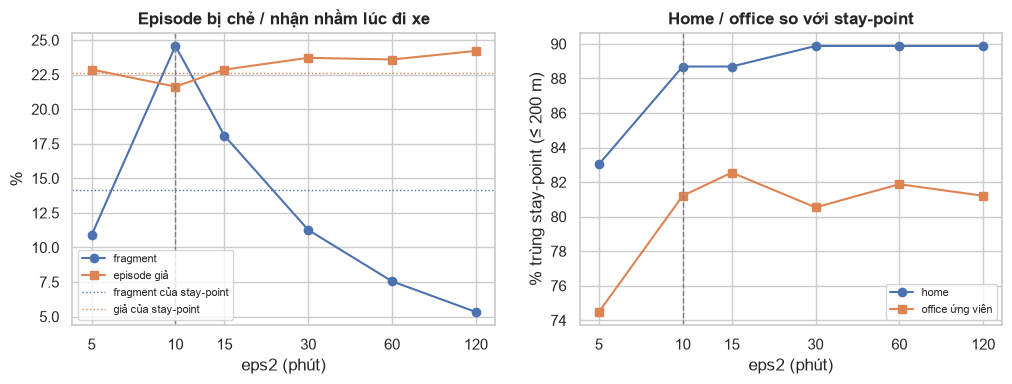

In [6]:
rows = [r15 if eps2 == 15 else evaluate(T10, eps2)[1] for eps2 in [5, 10, 15, 30, 60, 120]]
sweep = pd.DataFrame(rows)
fmt = {c: "{:.1%}".format for c in ["fragment", "fake", "home_agree", "office_agree"]}
display(sweep.round(2).assign(**{c: sweep[c].map(f) for c, f in fmt.items()}))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(sweep.eps2_min, sweep.fragment * 100, "o-", label="fragment")
axs[0].plot(sweep.eps2_min, sweep.fake * 100, "s-", label="episode giả")
axs[0].axhline(frag_share(st_ref) * 100, color="C0", ls=":", lw=1, label="fragment của stay-point")
axs[0].axhline(ref_fake * 100, color="C1", ls=":", lw=1, label="giả của stay-point")
axs[0].set(xscale="log", xlabel="eps2 (phút)", ylabel="%", title="Episode bị chẻ / nhận nhầm lúc đi xe")
axs[1].plot(sweep.eps2_min, sweep.home_agree * 100, "o-", label="home")
axs[1].plot(sweep.eps2_min, sweep.office_agree * 100, "s-", label="office ứng viên")
axs[1].set(xscale="log", xlabel="eps2 (phút)", ylabel="% trùng stay-point (≤ 200 m)", title="Home / office so với stay-point")
for ax in axs:
    ax.axvline(10, color="grey", ls="--", lw=1)
    ax.set_xticks(sweep.eps2_min); ax.set_xticklabels(sweep.eps2_min); ax.legend(fontsize=8)
savefig("07_st_dbscan_eps2"); plt.show()

## 2. Thưa hoá 10 s và 60 s có cho cùng kết quả không?

Chạy lại với ô 60 s ở eps2 = 15 phút, so với ô 10 s.

In [7]:
T60 = thin(60)
e60, r60 = evaluate(T60, 15)
h10, o10 = home_office(place_summary(e15, window_hours(e15)))
h60, o60 = home_office(place_summary(e60, window_hours(e60)))
print(f"Ô 60 s: {len(T60):,} điểm ({len(T60) / len(pts):.1%} số điểm gốc)")
display(pd.DataFrame([r15, r60], index=["10 s", "60 s"]).round(3))
print("Home 60 s trùng 10 s: user=%d, %.1f%%" % (lambda r: (r[0], r[1] * 100))(agree(h10, h60)))
print("Office 60 s trùng 10 s: user=%d, %.1f%%" % (lambda r: (r[0], r[1] * 100))(agree(o10, o60)))

Ô 60 s: 1,287,447 điểm (5.3% số điểm gốc)


,eps2_min,episodes,hours,median_dur_h,fragment,fake,home_users,home_agree,office_users,office_agree,run_s
10 s,15,23585,"86,722.6440",1.1670,0.1810,0.2290,171,0.8870,150,0.8260,8.2180
60 s,15,23683,"86,567.5070",1.1500,0.1820,0.2230,171,0.8690,150,0.8190,0.5520


Home 60 s trùng 10 s: user=171, 95.9%
Office 60 s trùng 10 s: user=150, 93.3%


## 3. Điều kiện quay lại sau khoảng không ghi: 200 m hay 400 m?

Mẫu kiểm tra ở trên cho thấy một chỗ khác nhau: stay 04:31–17:59 của stay-point **không có** episode tương ứng.
Điểm cuối trước gap 13 h và điểm đầu sau gap cách nhau 329 m, nên `w = 0`. Stay-point vẫn giữ stay này vì nó so mọi điểm với **điểm đầu của stay**:
hai điểm cùng nằm trong 200 m quanh điểm đầu thì có thể cách nhau tới 400 m.

So sánh hai điều kiện cho `w`: điểm sau gap cách điểm trước ≤ 200 m (đơn vị đo của NB06 mục 2) và ≤ 400 m (đường kính vùng stay-point chấp nhận).

In [8]:
w400 = np.where(nxt_same & (dt_next <= MAX_GAP) & (d_next <= 2 * EPS1), dt_next, 0.0)
gap = nxt_same & (dt_next >= 3600) & (dt_next <= MAX_GAP)
print(f"Khoảng không ghi 1–48 h: {gap.sum():,}; quay lại ≤ 200 m: {(gap & (d_next <= 200)).mean() / gap.mean():.1%}, "
      f"≤ 400 m: {(gap & (d_next <= 400)).mean() / gap.mean():.1%}")
e400, r400 = evaluate(thin(10, w400), 15)
cmp_w = pd.DataFrame([r15, r400], index=["≤ 200 m", "≤ 400 m"])
display(cmp_w.round(3))
print(f"Tổng giờ stay-point để so: {st_ref.dur_h.sum():,.0f}")
h400, _ = home_office(place_summary(e400, window_hours(e400)))
print("Home 400 m trùng 200 m: user=%d, %.1f%%" % (lambda r: (r[0], r[1] * 100))(agree(h10, h400)))
print("Mẫu kiểm tra, cùng user/ngày với điều kiện 400 m:"); display(win(e400))

Khoảng không ghi 1–48 h: 22,221; quay lại ≤ 200 m: 44.2%, ≤ 400 m: 60.1%


,eps2_min,episodes,hours,median_dur_h,fragment,fake,home_users,home_agree,office_users,office_agree,run_s
≤ 200 m,15,23585,"86,722.6440",1.1670,0.1810,0.2290,171,0.8870,150,0.8260,8.2180
≤ 400 m,15,27657,"124,022.6690",1.4110,0.1750,0.2490,174,0.8150,154,0.8240,7.8970


Tổng giờ stay-point để so: 101,885
Home 400 m trùng 200 m: user=171, 83.6%
Mẫu kiểm tra, cùng user/ngày với điều kiện 400 m:


,start,end,dur_h,lat,lon,place
25019,2011-12-17 23:42:39,2011-12-18 01:14:58,1.5386,24.4569,118.0875,490
25020,2011-12-18 01:34:20,2011-12-18 02:05:26,0.5183,24.4686,118.0867,491
25021,2011-12-18 02:34:43,2011-12-18 03:14:41,0.6661,24.4579,118.0796,492
25022,2011-12-18 03:22:44,2011-12-18 03:55:57,0.5536,24.4564,118.0730,493
25023,2011-12-18 04:26:00,2011-12-18 17:58:52,13.5478,24.4576,118.0863,490
25024,2011-12-18 18:02:30,2011-12-18 18:32:06,0.4933,24.4554,118.0708,493
25025,2011-12-18 18:32:06,2011-12-18 18:53:40,0.3594,24.4568,118.0686,494
25026,2011-12-18 18:56:12,2011-12-18 19:43:03,0.7808,24.4476,118.0694,495
25027,2011-12-18 19:56:13,2011-12-18 20:48:43,0.8750,24.4444,118.0651,496
25028,2011-12-18 20:48:43,2011-12-18 22:13:21,1.4106,24.4448,118.0623,497
